# Hành vi khách hàng

| # | Câu hỏi | 
|---|---|
| 1 | Quy mô khách hàng và giá trị mỗi khách mang lại? | 
| 2 | Tăng trưởng đến từ khách mới hay khách cũ? | 
| 3 | Nên chia khách thành những nhóm nào để hành động? |
| 4 | Khách mua vào lúc nào? Có mùa cao điểm không? | 
| 5 | Một giỏ hàng điển hình trông ra sao? | 
| 6 | Khách trả tiền bằng cách nào? Trả góp ảnh hưởng gì? |
| 7 | Khách có quay lại không? Sau bao lâu? | 
| 8 | Tóm lại, insight quan trọng nhất là gì? | Tổng kết |

### Quy ước
- **Đối tượng phân tích**: Khách hàng và đơn hàng
- **Khách hàng** = `customer_key` trong `dim_customer` (1 dòng / `customer_unique_id`) → đếm được khách mua lặp lại.
- **Đơn hợp lệ** = loại `canceled`, `unavailable` và đơn không có sản phẩm nào.
- **Doanh thu (GMV)** = giá sản phẩm + phí ship của đơn hợp lệ, đơn vị R$.
- **Kỳ phân tích** của các biểu đồ theo thời gian: cửa sổ xu hướng chung của mọi notebook, suy ra từ dữ liệu trong `common.connect()` (hiện là 01/2017 → 08/2018).

## 0. Kết nối lakehouse & nạp dữ liệu Silver

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
from common import *   # kết nối, kỳ phân tích, bảng màu, hàm trục, RFM

con, P = connect(["fact_payments", "dim_product", "dim_category"])

Kỳ này 01–08/2018 | cùng kỳ 01–08/2017 | xu hướng 01/2017–08/2018 | 98,059 đơn, 96,817 đơn hợp lệ


In [2]:
apply_theme()
DOW_LABELS = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]

def add_share(df, *cols):
    # Thêm cột <col>_share = tỷ trọng của từng dòng trên tổng cột
    for c in cols:
        df[f"{c}_share"] = df[c] / df[c].sum()
    return df

# Định dạng số kiểu Việt Nam (1.234,5) cho phần nhận xét
def num(x, d=0):
    return f"{x:,.{d}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def pct(x, d=1, signed=False):
    return ("+" if signed and x > 0 else "") + num(x * 100, d) + "%"

def money(x, d=0):
    return "R$ " + num(x, d)

### 0.1 Bảng phân tích đơn hàng (`orders_valid`)
Mỗi **đơn hợp lệ** 1 dòng, lấy từ `order_base` (tạo sẵn trong `connect()`): giá trị đơn, số sản phẩm, thời điểm đặt (giờ, thứ, tháng), bang của khách;
ghép thêm ngành hàng chính (item đắt nhất), hình thức thanh toán chính và số kỳ trả góp (`order_payment` của `common/tables.py`),
và **thứ tự đơn của khách** (`order_seq`) để phân biệt đơn đầu tiên với đơn mua lại.

In [3]:
create_order_payment()
con.execute("""
-- Ngành hàng chính của đơn = ngành (tên tiếng Anh, thiếu thì 'unknown', giống main_category của Gold) của item có giá cao nhất
CREATE OR REPLACE TABLE order_category AS
WITH items_c AS (
    SELECT i.*, coalesce(c.product_category_name_english, 'unknown') AS category
    FROM fact_order_items i
    LEFT JOIN dim_product p USING (product_key)
    LEFT JOIN dim_category c USING (category_key)
), ranked AS (
    SELECT *, row_number() OVER (PARTITION BY order_key ORDER BY price DESC, order_item_id) AS rn FROM items_c
)
SELECT order_key,
       count(DISTINCT category)              AS n_categories,
       max(category) FILTER (WHERE rn = 1)   AS main_category
FROM ranked GROUP BY order_key;

-- 1 dòng / đơn hợp lệ, kèm thứ tự đơn của từng khách -> phân biệt đơn đầu tiên / đơn mua lại
CREATE OR REPLACE TABLE orders_valid AS
SELECT o.order_key, o.customer_key, o.order_status, o.customer_state, o.customer_city,
       o.n_items, o.n_products, oc.n_categories, o.n_sellers,
       o.product_value, o.freight_value, oc.main_category,
       po.payment_value, po.installments, po.n_payment_types, po.used_voucher,
       coalesce(po.payment_type, 'unknown') AS payment_type,
       o.order_purchase_timestamp AS purchase_ts, o.purchase_date, o.purchase_month, o.purchase_hour, o.dow, o.gmv,
       row_number() OVER w AS order_seq,
       row_number() OVER w > 1 AS is_repeat_order,
       date_diff('day', lag(o.purchase_date) OVER w, o.purchase_date) AS days_since_prev   -- số ngày lịch
FROM order_base o
LEFT JOIN order_category oc ON oc.order_key = o.order_key
LEFT JOIN order_payment po ON po.order_key = o.order_key
WHERE o.is_valid = 1
WINDOW w AS (PARTITION BY o.customer_key ORDER BY o.order_purchase_timestamp, o.order_key);
""")

print(f"Tổng đơn: {scalar('SELECT count(*) FROM order_base'):,} | "
      f"Đơn hợp lệ: {scalar('SELECT count(*) FROM orders_valid'):,}")
q("""SELECT order_status, count(*) AS orders, sum(is_valid) AS valid_orders
     FROM order_base GROUP BY 1 ORDER BY 2 DESC""")

Tổng đơn: 98,059 | Đơn hợp lệ: 96,817


,order_status,orders,valid_orders
0,delivered,95105,95105
1,shipped,1098,1097
2,canceled,625,0
3,unavailable,609,0
4,invoiced,314,312
5,processing,301,301
6,created,5,0
7,approved,2,2


### 0.2 Bảng phân tích khách hàng (`cust_base`)
Mỗi khách 1 dòng: số đơn (Frequency), tổng chi tiêu (Monetary), số ngày từ lần mua cuối (Recency), cohort (tháng mua đầu),
ngành hàng / hình thức thanh toán của đơn đầu tiên, số ngày tới đơn thứ hai.

In [4]:
SNAPSHOT = scalar("SELECT max(purchase_date) + INTERVAL '1' DAY FROM orders_valid")   # ngày chốt số liệu

con.execute(f"""
CREATE OR REPLACE TABLE cust_base AS
SELECT customer_key,
       count(*)                     AS frequency,
       sum(gmv)                     AS monetary,
       avg(gmv)                     AS avg_order_value,
       sum(n_items)                 AS total_items,
       count(DISTINCT main_category) AS n_categories,
       min(purchase_ts)             AS first_purchase,
       max(purchase_ts)             AS last_purchase,
       date_diff('day', max(purchase_date), DATE '{SNAPSHOT}') AS recency_days,
       count(*) > 1                 AS is_repeat,
       arbitrary(purchase_month)  FILTER (WHERE order_seq = 1) AS cohort_month,
       arbitrary(customer_state)  FILTER (WHERE order_seq = 1) AS state,
       arbitrary(main_category)   FILTER (WHERE order_seq = 1) AS first_category,
       arbitrary(payment_type)    FILTER (WHERE order_seq = 1) AS first_payment_type,
       arbitrary(gmv)             FILTER (WHERE order_seq = 1) AS first_order_value,
       arbitrary(days_since_prev) FILTER (WHERE order_seq = 2) AS days_to_2nd_order
FROM orders_valid
GROUP BY customer_key
""")
print("Ngày chốt số liệu (snapshot):", SNAPSHOT)
print(f"Số khách hàng có đơn hợp lệ: {scalar('SELECT count(*) FROM cust_base'):,}")

Ngày chốt số liệu (snapshot): 2018-09-04
Số khách hàng có đơn hợp lệ: 93,664


### 0.3 Kỳ phân tích

In [5]:
print(f"Kỳ phân tích (chung cho mọi notebook): {P.m_start[:7]} → {P.m_end[:7]}")
q(f"SELECT date_format(purchase_month, '%Y-%m') AS month, count(*) AS orders FROM orders_valid WHERE {P.in_period} GROUP BY 1 ORDER BY 1").set_index("month").T

Kỳ phân tích (chung cho mọi notebook): 2017-01 → 2018-08


month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
orders,786,1715,2616,2353,3625,3200,3914,4269,4214,4547,7420,5613,7162,6612,7166,6526,6765,6022,5667,6335


## 1. KPI khách hàng — quy mô và giá trị mỗi khách
Quy mô toàn sàn (GMV, số đơn, AOV) và tỷ trọng phí ship xem `executive_overview` §1; ở đây chỉ giữ các chỉ số **trên mỗi khách hàng**.

In [6]:
k = q("""
SELECT count(DISTINCT customer_key)              AS customers,
       count(*)                                  AS orders,
       sum(gmv)                                  AS gmv,
       avg(n_items)                              AS items_per_order,
       sum(gmv) FILTER (WHERE is_repeat_order)   AS gmv_repeat_orders
FROM orders_valid""").iloc[0]
kc = q("""
SELECT avg(CAST(is_repeat AS INTEGER))          AS repeat_rate,
       avg(monetary)                            AS clv,
       sum(monetary) FILTER (WHERE is_repeat)   AS gmv_repeat_cust
FROM cust_base""").iloc[0]

pd.DataFrame({
    "KPI": ["Khách hàng (unique)", "Số đơn / khách", "Doanh thu / khách (CLV lịch sử)", "Sản phẩm / đơn",
            "% khách mua lại (≥2 đơn)", "% doanh thu từ khách mua lại", "% doanh thu từ đơn mua lại"],
    "Giá trị": [num(k.customers), num(k.orders / k.customers, 3), money(kc.clv, 2), num(k.items_per_order, 2),
                pct(kc.repeat_rate, 2), pct(kc.gmv_repeat_cust / k.gmv, 2), pct(k.gmv_repeat_orders / k.gmv, 2)],
})

,KPI,Giá trị
0,Khách hàng (unique),93.664
1,Số đơn / khách,"1,034"
2,Doanh thu / khách (CLV lịch sử),"R$ 165,76"
3,Sản phẩm / đơn,"1,14"
4,% khách mua lại (≥2 đơn),"3,02%"
5,% doanh thu từ khách mua lại,"5,62%"
6,% doanh thu từ đơn mua lại,"2,96%"


> **🔎 Kết quả chính**
> - ~95 nghìn khách; số đơn / khách chỉ 1,03 — chỉ 3,0% khách mua từ 2 lần trở lên và nhóm này đóng góp 5,7% doanh thu. → Mô hình kinh doanh hiện tại phụ thuộc gần như hoàn toàn vào thu hút khách mới.
> - Mỗi đơn trung bình chỉ 1,14 sản phẩm.

## 2. Tăng trưởng khách hàng — khách mới hay khách quay lại?

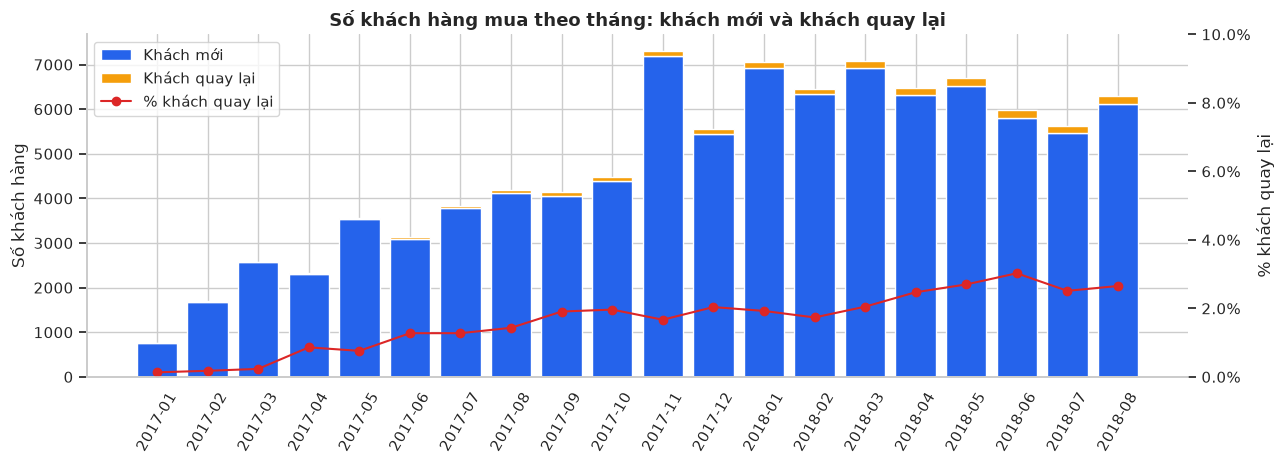

,month,active_customers,new_customers,returning_customers,returning_share,orders,gmv,gmv_mom
0,2017-01,753,752,1,0.001,786,136736.81,NaN
1,2017-02,1690,1687,3,0.002,1715,282977.70,1.070
2,2017-03,2576,2570,6,0.002,2616,425503.89,0.504
3,2017-04,2321,2301,20,0.009,2353,403527.50,-0.052
4,2017-05,3555,3528,27,0.008,3625,581127.99,0.440
5,2017-06,3137,3097,40,0.013,3200,498926.74,-0.141
6,2017-07,3841,3792,49,0.013,3914,574812.07,0.152
7,2017-08,4188,4128,60,0.014,4269,660975.68,0.150
8,2017-09,4141,4062,79,0.019,4214,714189.99,0.081
9,2017-10,4481,4393,88,0.020,4547,764756.03,0.071


In [7]:
# Khách mới của tháng = khách có đơn đầu tiên trong tháng; khách quay lại = khách mua trong tháng nhưng đã mua từ trước.
# (Khách vừa mua đơn đầu vừa mua thêm trong cùng tháng được tính là khách mới -> không đếm trùng.)
growth = q(f"""
SELECT purchase_month,
       count(DISTINCT customer_key)                              AS active_customers,
       count(DISTINCT customer_key) FILTER (WHERE order_seq = 1) AS new_customers,
       count(*)                                                  AS orders,
       sum(gmv)                                                  AS gmv
FROM orders_valid WHERE {P.in_period}
GROUP BY 1 ORDER BY 1""")
growth["returning_customers"] = growth.active_customers - growth.new_customers
growth["returning_share"] = growth.returning_customers / growth.active_customers
growth["gmv_mom"] = growth.gmv.pct_change()
growth["month"] = growth.purchase_month.dt.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.bar(growth.month, growth.new_customers, color=C_MAIN, label="Khách mới")
ax.bar(growth.month, growth.returning_customers, bottom=growth.new_customers, color=C_ACCENT, label="Khách quay lại")
ax.set_title("Số khách hàng mua theo tháng: khách mới và khách quay lại")
ax.set_ylabel("Số khách hàng")
ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx()
ax2.plot(growth.month, growth.returning_share, color=C_BAD, marker="o", lw=1.5, label="% khách quay lại")
pct_axis(ax2); ax2.grid(False); ax2.set_ylim(0, max(0.1, growth.returning_share.max() * 1.3)); ax2.set_ylabel("% khách quay lại")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()

growth[["month", "active_customers", "new_customers", "returning_customers", "returning_share", "orders", "gmv", "gmv_mom"]].round(3)

In [8]:
peak = growth.loc[growth.new_customers.idxmax()]
year, mon = growth.purchase_month.dt.year, growth.purchase_month.dt.month
prev_h1 = growth[(year == P.year_prev) & (mon <= 6)]      # 6 tháng đầu năm trước
cur_year = growth[year == P.year_cur]
peak_cur = cur_year.loc[cur_year.new_customers.idxmax()]
min_cur = cur_year.loc[cur_year.new_customers.idxmin()]
last = growth.iloc[-1]
new_share = 1 - growth.returning_share

print("=== Tỷ trọng khách mới / khách quay lại ===")
print(f"Tỷ lệ khách mới mỗi tháng               : {new_share.min():.1%} – {new_share.max():.1%}")
print(f"Tỷ lệ khách quay lại TB 6 tháng đầu {P.year_prev}: {prev_h1.returning_share.mean():.2%}")
print(f"Tỷ lệ khách quay lại TB năm {P.year_cur}        : {cur_year.returning_share.mean():.2%}")

print("=== Tháng có nhiều khách mới nhất (toàn kỳ) ===")
print(f"Tháng {peak.month}: {int(peak.new_customers):,} khách mới | "
      f"GMV {peak.gmv:,.0f} | GMV so với tháng trước {peak.gmv_mom:+.1%}")

print(f"=== Năm {P.year_cur} ===")
print(f"Khách mới/tháng thấp nhất: {int(min_cur.new_customers):,} ({min_cur.month})")
print(f"Khách mới/tháng cao nhất : {int(peak_cur.new_customers):,} ({peak_cur.month})")
print(f"Tháng cuối kỳ {last.month}: {int(last.new_customers):,} khách mới "
      f"-> thấp hơn đỉnh {P.year_cur} {1 - last.new_customers / peak_cur.new_customers:.1%}")

=== Tỷ trọng khách mới / khách quay lại ===
Tỷ lệ khách mới mỗi tháng               : 97.0% – 99.9%
Tỷ lệ khách quay lại TB 6 tháng đầu 2017: 0.57%
Tỷ lệ khách quay lại TB năm 2018        : 2.38%
=== Tháng có nhiều khách mới nhất (toàn kỳ) ===
Tháng 2017-11: 7,190 khách mới | GMV 1,171,920 | GMV so với tháng trước +53.2%
=== Năm 2018 ===
Khách mới/tháng thấp nhất: 5,473 (2018-07)
Khách mới/tháng cao nhất : 6,930 (2018-03)
Tháng cuối kỳ 2018-08: 6,127 khách mới -> thấp hơn đỉnh 2018 11.6%


## 3. Phân khúc khách hàng RFM
Cả ba chiều đều chấm **1–5**:
- **R** (số ngày từ lần mua cuối) và **M** (tổng chi tiêu): theo **ngưỡng ngũ phân vị** (khách cùng giá trị luôn cùng điểm → ổn định giữa các lần chạy).
- **F** (số đơn hợp lệ): ngũ phân vị của F đều bằng 1 (≈97% khách chỉ mua 1 lần), nên không cắt theo phân vị được →
  dùng **ngưỡng cố định theo số đơn**: F1 = 1 đơn, F2 = 2 đơn, F3 = 3 đơn, F4 = 4 đơn, F5 = ≥ 5 đơn.
  Các mức F3–F5 rất ít khách nhưng vẫn giữ riêng để mã RFM (vd. `545`) đúng chuẩn 5×5×5 và tách được nhóm khách mua nhiều lần nhất.

| Phân khúc | Quy tắc | Ý nghĩa hành động |
|---|---|---|
| Champions | F ≥ 2 và R ≥ 4 | Mua lại & mới mua gần đây → chương trình VIP/thành viên |
| Loyal – cần giữ chân | F ≥ 2 và R ≤ 3 | Từng mua lại nhưng lâu không quay lại → win-back ưu tiên |
| Khách mới | F = 1, R ≥ 4 | Mới mua lần đầu gần đây → kích hoạt đơn thứ 2 (cross-sell, freeship theo ngưỡng) |
| Cần nuôi dưỡng | F = 1, R = 3 | Đã một thời gian chưa quay lại → email/remarketing |
| Giá trị cao sắp mất | F = 1, R ≤ 2, M ≥ 4 | Chi nhiều nhưng lâu không mua → ưu đãi win-back |
| Đã rời bỏ | F = 1, R ≤ 2, M ≤ 3 | Giá trị thấp, lâu không mua → chi phí thấp nhất |

Bảng `customer_rfm` và quy tắc phân khúc do `create_customer_rfm()` của `common/rfm.py` tạo, dùng chung với `executive_overview` §3. Ngưỡng R, M, F cụ thể được in ra ở cuối phần này.

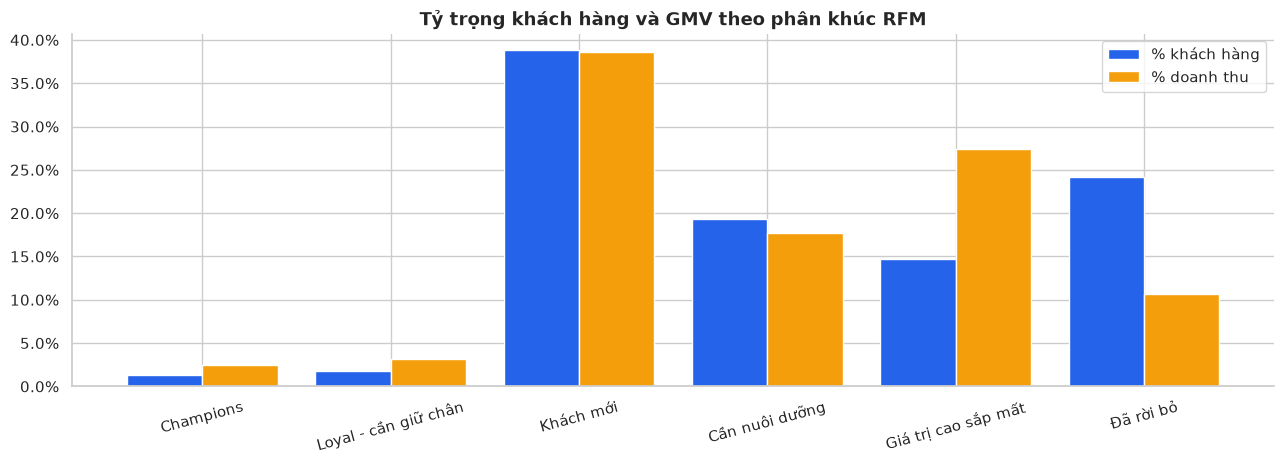

,segment,customers,gmv,avg_recency,avg_frequency,avg_monetary,customers_share,gmv_share
0,Champions,1216,388708.09,97.285,2.16,319.661,0.013,0.025
1,Loyal - cần giữ chân,1614,483473.45,329.310,2.08,299.550,0.017,0.031
2,Khách mới,36342,5993550.07,98.657,1.00,164.921,0.388,0.386
3,Cần nuôi dưỡng,18117,2753710.68,229.347,1.00,151.996,0.193,0.177
4,Giá trị cao sắp mất,13738,4258923.76,402.838,1.00,310.010,0.147,0.274
5,Đã rời bỏ,22637,1647640.36,403.672,1.00,72.785,0.242,0.106


In [9]:
rfm = create_customer_rfm()   # bảng customer_rfm: recency_days, frequency, monetary, R, F, M, rfm_code, segment

seg = q("""
SELECT segment, count(*) AS customers, sum(monetary) AS gmv,
       avg(recency_days) AS avg_recency, avg(frequency) AS avg_frequency, avg(monetary) AS avg_monetary
FROM customer_rfm GROUP BY 1""")
seg = add_share(ordered(seg, "segment", SEG_ORDER, drop_missing=True), "customers", "gmv")

fig, ax = plt.subplots(figsize=(13, 4.8))
grouped_bar(ax, seg.segment, {"% khách hàng": (seg.customers_share, C_MAIN), "% doanh thu": (seg.gmv_share, C_ACCENT)})
ax.tick_params(axis="x", rotation=15); pct_axis(ax)
ax.set_title("Tỷ trọng khách hàng và GMV theo phân khúc RFM")
plt.tight_layout(); plt.show()
seg.round(3)

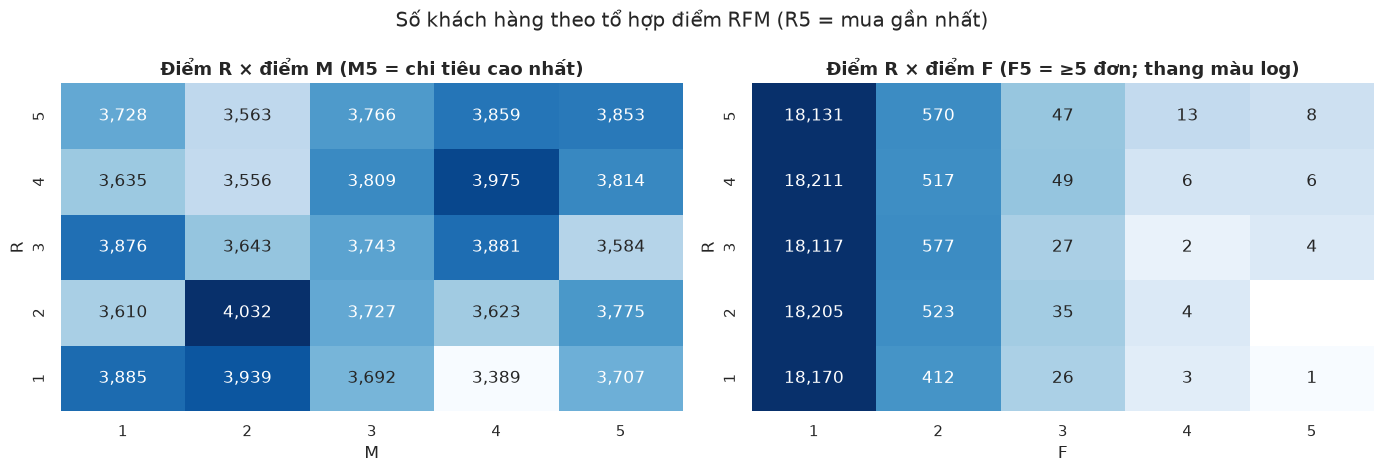

,dim,score,min_value,max_value,customers
0,F,1,1.00,1.00,90834
1,F,2,2.00,2.00,2599
2,F,3,3.00,3.00,184
3,F,4,4.00,4.00,28
4,F,5,5.00,16.00,19
5,M,1,9.59,55.31,18734
6,M,2,55.32,87.41,18733
7,M,3,87.42,133.05,18737
8,M,4,133.06,209.15,18727
9,M,5,209.16,13664.08,18733


In [10]:
# R × F dùng thang log (LogNorm) để các ô F3-F5 rất ít khách vẫn nhìn thấy
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col, title, norm in [(axes[0], "M", "Điểm R × điểm M (M5 = chi tiêu cao nhất)", None),
                             (axes[1], "F", "Điểm R × điểm F (F5 = ≥5 đơn; thang màu log)", LogNorm(vmin=1))]:
    grid = q(f'SELECT R AS "R", {col} AS "{col}", count(*) AS customers FROM customer_rfm GROUP BY 1, 2')
    gp = (grid.pivot(index="R", columns=col, values="customers")
              .reindex(index=[5, 4, 3, 2, 1], columns=[1, 2, 3, 4, 5]).fillna(0))
    sns.heatmap(gp, annot=True, fmt=",.0f", cmap="Blues", norm=norm, ax=ax, cbar=False); ax.grid(False)
    ax.set_title(title)
fig.suptitle("Số khách hàng theo tổ hợp điểm RFM (R5 = mua gần nhất)")
plt.tight_layout(); plt.show()

# Ngưỡng thực tế của từng điểm R / F / M
rfm_range = pd.concat([
    q(f"""SELECT '{d}' AS dim, {d} AS score, min({c}) AS min_value, max({c}) AS max_value, count(*) AS customers
          FROM customer_rfm GROUP BY 1, 2""")
    for d, c in [("R", "recency_days"), ("F", "frequency"), ("M", "monetary")]
]).sort_values(["dim", "score"]).reset_index(drop=True)
rfm_range.round(2)

> **Nhận xét:**
> - Khách trung thành (Champions + Loyal) chỉ 3,0% khách, 5,7% doanh thu.
> - "Khách mới" (mua 1 lần trong ~6 tháng gần nhất) là nhóm lớn nhất: 39% khách → 39% doanh thu, cần kích hoạt đơn thứ 2 trước khi trôi sang nhóm sắp mất.
> - "Giá trị cao sắp mất" chỉ 15% khách nhưng tạo 27% doanh thu (≈309 BRL/khách, gần gấp đôi khách mới ≈165 BRL) → cần win-back trước khi mất hẳn.
> - 24% khách đã "rời bỏ" với giá trị thấp (11% doanh thu) → không nên tốn ngân sách giữ chân.
> - Ngưỡng Recency: R5 ≤ 99 ngày (~3 tháng), R4 ≤ 183 ngày (~6 tháng), R3 ≤ 274 ngày (~9 tháng), R1–2 > 274 ngày.

## 4. Thời điểm mua sắm — khách mua vào lúc nào?

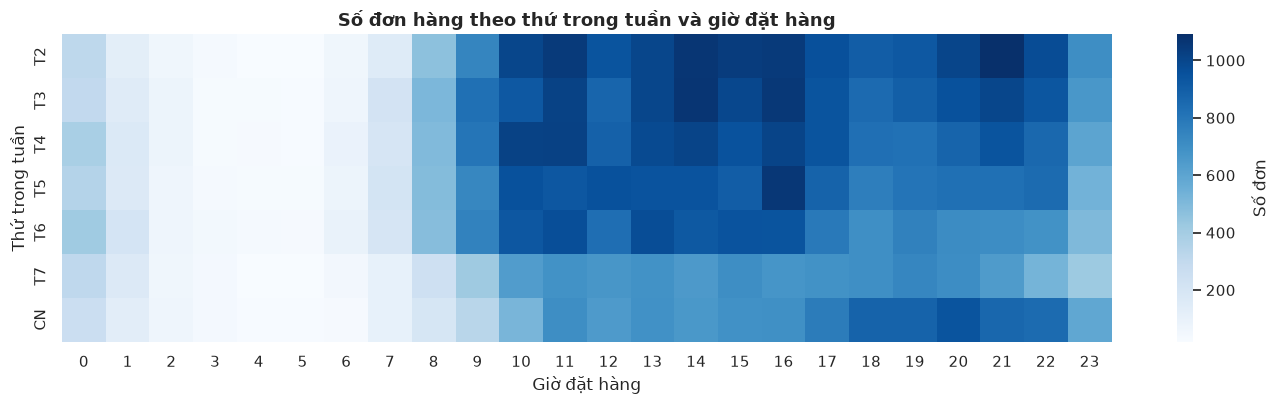

In [11]:
dh = q(f"SELECT dow, purchase_hour, count(*) AS orders FROM orders_valid WHERE {P.in_period} GROUP BY 1, 2")
heat = dh.pivot(index="dow", columns="purchase_hour", values="orders").fillna(0).sort_index()
heat.index = [DOW_LABELS[i - 1] for i in heat.index]
fig, ax = plt.subplots(figsize=(14, 4.2))
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "Số đơn"}); ax.grid(False)
ax.set_title("Số đơn hàng theo thứ trong tuần và giờ đặt hàng"); ax.set_xlabel("Giờ đặt hàng"); ax.set_ylabel("Thứ trong tuần")
plt.tight_layout(); plt.show()

> **Nhận xét:**
> - Các đơn thường đặt vào đầu tuần thay vì cuối tuần
> - Các khung giờ thường được đặt nhiều nhất vào 11h, 14h, 16h, 21h

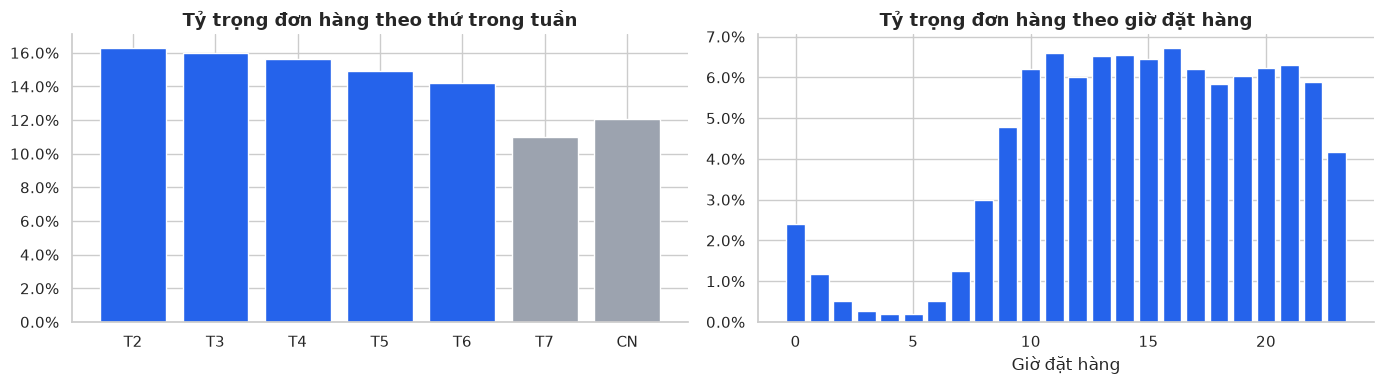

Tỷ trọng theo buổi:
 daypart
Đêm (0-5h)         4.8%
Sáng (6-11h)      22.3%
Chiều (12-17h)    38.5%
Tối (18-23h)      34.5%


,dow,orders,aov,orders_share
0,T2,15717,161.796,0.163
1,T3,15421,159.988,0.160
2,T4,15076,159.539,0.156
3,T5,14391,159.802,0.149
4,T6,13718,162.758,0.142
5,T7,10584,162.120,0.110
6,CN,11620,155.869,0.120


In [12]:
by_dow = add_share(q(f"""SELECT dow, count(*) AS orders, avg(gmv) AS aov
                         FROM orders_valid WHERE {P.in_period} GROUP BY 1 ORDER BY 1"""), "orders")
by_hour = add_share(q(f"""SELECT purchase_hour, count(*) AS orders, avg(gmv) AS aov
                          FROM orders_valid WHERE {P.in_period} GROUP BY 1 ORDER BY 1"""), "orders")

def daypart(h):
    return "Đêm (0-5h)" if h < 6 else "Sáng (6-11h)" if h < 12 else "Chiều (12-17h)" if h < 18 else "Tối (18-23h)"
by_daypart = by_hour.assign(daypart=by_hour.purchase_hour.map(daypart)).groupby("daypart", sort=False)["orders_share"].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar([DOW_LABELS[i - 1] for i in by_dow.dow], by_dow.orders_share,
            color=[C_MAIN if d < 6 else C_GREY for d in by_dow.dow])
axes[0].set_title("Tỷ trọng đơn hàng theo thứ trong tuần"); pct_axis(axes[0])
axes[1].bar(by_hour.purchase_hour, by_hour.orders_share, color=C_MAIN)
axes[1].set_title("Tỷ trọng đơn hàng theo giờ đặt hàng"); axes[1].set_xlabel("Giờ đặt hàng"); pct_axis(axes[1])
plt.tight_layout(); plt.show()
print("Tỷ trọng theo buổi:\n", by_daypart.map("{:.1%}".format).to_string())
by_dow.assign(dow=[DOW_LABELS[i - 1] for i in by_dow.dow]).round(3)

> **Nhận xét:**
> - Khách mua nhiều nhất vào T2 & T3 (~16% mỗi ngày), thấp nhất T7 (~11%). Trung bình ngày thường 15,4% / ngày so với cuối tuần 11,5% / ngày.
> - Buổi chiều chiếm 39%, buổi tối 34%, sáng 22%, đêm chỉ 5%.
> - AOV theo thứ chỉ dao động R$ 156–R$ 163 → thời điểm ảnh hưởng số lượng đơn, không ảnh hưởng giá trị giỏ hàng.

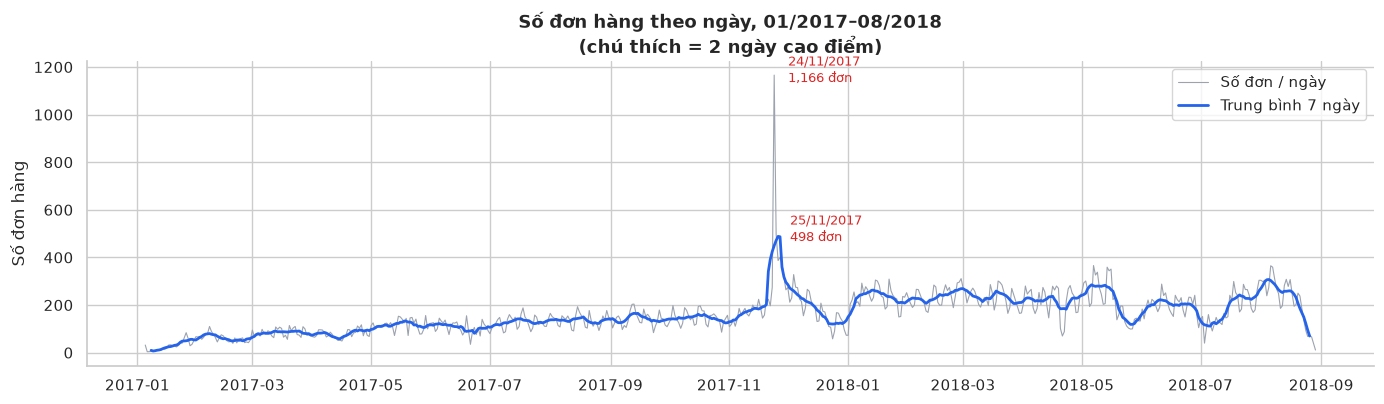

In [13]:
daily = q("SELECT purchase_date, count(*) AS orders, sum(gmv) AS gmv FROM orders_valid GROUP BY 1 ORDER BY 1")
daily = daily[(daily.purchase_date >= pd.Timestamp(P.m_start)) &
              (daily.purchase_date < pd.Timestamp(P.m_end) + pd.offsets.MonthBegin(1))].copy()
daily["ma7"] = daily.orders.rolling(7, center=True).mean()
top_days = daily.nlargest(5, "orders").assign(vs_ma7=lambda d: d.orders / d.ma7)

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(daily.purchase_date, daily.orders, color=C_GREY, lw=0.8, label="Số đơn / ngày")
ax.plot(daily.purchase_date, daily.ma7, color=C_MAIN, lw=2, label="Trung bình 7 ngày")
for _, r in top_days.head(2).iterrows():
    ax.annotate(f"{r.purchase_date:%d/%m/%Y}\n{r.orders:,.0f} đơn", (r.purchase_date, r.orders),
                xytext=(10, -5), textcoords="offset points", fontsize=9, color=C_BAD)
ax.set_title(f"Số đơn hàng theo ngày, {P.label_trend}\n(chú thích = 2 ngày cao điểm)"); ax.set_ylabel("Số đơn hàng"); ax.legend()
plt.tight_layout(); plt.show()

> **Nhận xét:** Ngày 24/11/2017 (Black Friday) có 1.166 đơn, gấp ~2,6 lần trung bình 7 ngày: đỉnh đơn hàng lớn nhất trong kỳ.

## 5. Giỏ hàng & mức chi tiêu

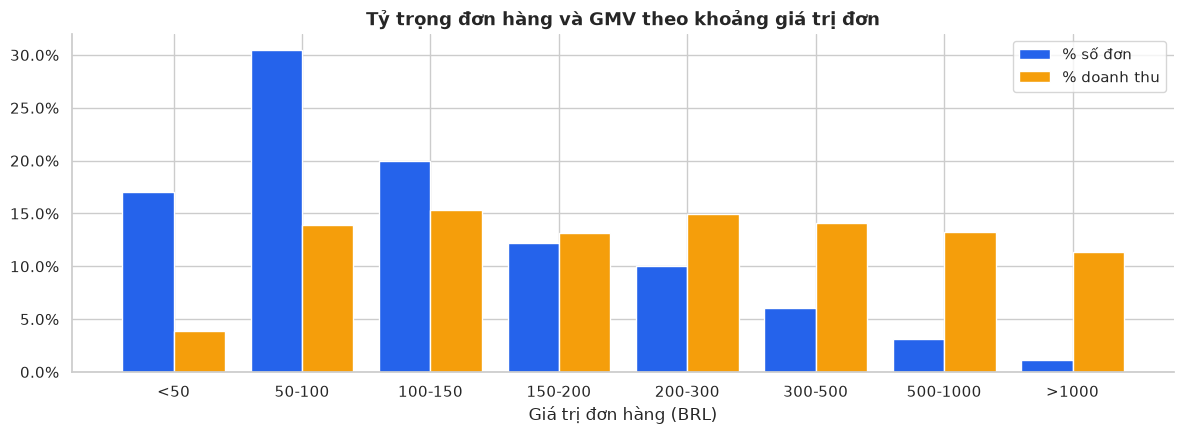

Giá trị đơn — P25/P50/P75/P90/P99: [61.9, 105.3, 176.8, 307.4, 1057.3]


,value_band,orders,gmv,freight_share,avg_installments,orders_share,gmv_share
0,<50,16506,608555.73,0.355,1.520,0.170,0.039
1,50-100,29537,2164221.06,0.230,2.274,0.305,0.139
2,100-150,19290,2377975.41,0.169,2.994,0.199,0.153
3,150-200,11794,2036460.24,0.149,3.479,0.122,0.131
4,200-300,9680,2318791.76,0.131,4.090,0.100,0.149
5,300-500,5862,2189756.91,0.107,4.802,0.061,0.141
6,500-1000,3029,2061419.32,0.076,5.874,0.031,0.133
7,>1000,1119,1768825.98,0.053,6.575,0.012,0.114


In [14]:
VALUE_BINS = [(50, "<50"), (100, "50-100"), (150, "100-150"), (200, "150-200"), (300, "200-300"),
              (500, "300-500"), (1000, "500-1000")]
VALUE_LABELS = [lab for _, lab in VALUE_BINS] + [">1000"]

bands = q(f"""
SELECT {band_sql("gmv", VALUE_BINS, ">1000")} AS value_band,
       count(*) AS orders, sum(gmv) AS gmv,
       sum(freight_value) / sum(gmv) AS freight_share,
       avg(installments) AS avg_installments
FROM orders_valid GROUP BY 1""")
bands = add_share(ordered(bands, "value_band", VALUE_LABELS, drop_missing=True), "orders", "gmv")

fig, ax = plt.subplots(figsize=(12, 4.5))
grouped_bar(ax, bands.value_band, {"% số đơn": (bands.orders_share, C_MAIN), "% doanh thu": (bands.gmv_share, C_ACCENT)})
pct_axis(ax); ax.set_title("Tỷ trọng đơn hàng và GMV theo khoảng giá trị đơn"); ax.set_xlabel("Giá trị đơn hàng (BRL)")
plt.tight_layout(); plt.show()

qs = scalar(f"SELECT {quantile_sql('gmv', [0.25, 0.5, 0.75, 0.9, 0.99])} FROM orders_valid")
print("Giá trị đơn — P25/P50/P75/P90/P99:", [round(v, 1) for v in qs])
bands.round(3)

> **Nhận xét:**
> - Trung vị giá trị đơn ~R$ 105, 75% đơn dưới R$ 177, nhưng có đuôi dài (P99 ≈ R$ 1.055).
> - Khoảng R$ 50-100 chiếm nhiều đơn nhất (31% đơn) nhưng chỉ 14% doanh thu; ngược lại, đơn ≥ R$300 chỉ 10% số đơn nhưng tạo ra 39% doanh thu → nhóm đơn giá trị cao rất quan trọng.
> - Phí ship chiếm 35% giá trị các đơn < R$50 (so với 5% ở đơn > R$1.000) → Nên có chính sách freeship theo ngưỡng (vd. từ R$100) có thể kích khách gom đơn.
> - Số kỳ trả góp tăng đều theo giá trị đơn (1,5 → 6,6 kỳ).

% đơn có >1 sản phẩm khác nhau: 3.3% | >1 ngành hàng: 0.8% | >1 người bán: 1.3%


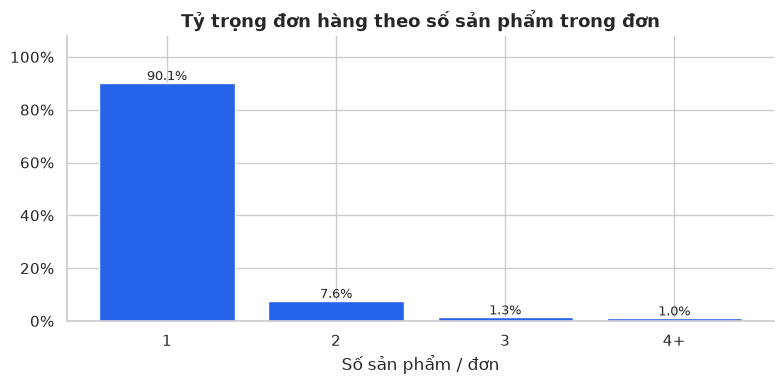

In [15]:
ipo = add_share(q("""
SELECT CASE WHEN n_items >= 4 THEN '4+' ELSE CAST(n_items AS VARCHAR) END AS n_items_b,
       count(*) AS orders, avg(gmv) AS aov
FROM orders_valid GROUP BY 1 ORDER BY 1"""), "orders")
multi = q("""
SELECT avg(CAST(n_products > 1 AS INTEGER))   AS multi_product,
       avg(CAST(n_categories > 1 AS INTEGER)) AS multi_category,
       avg(CAST(n_sellers > 1 AS INTEGER))    AS multi_seller
FROM orders_valid""").iloc[0]
print(f"% đơn có >1 sản phẩm khác nhau: {multi.multi_product:.1%} | >1 ngành hàng: {multi.multi_category:.1%} "
      f"| >1 người bán: {multi.multi_seller:.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ipo.n_items_b, ipo.orders_share, color=C_MAIN)
for i, r in enumerate(ipo.itertuples()):
    ax.text(i, r.orders_share, f"{r.orders_share:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_title("Tỷ trọng đơn hàng theo số sản phẩm trong đơn"); ax.set_xlabel("Số sản phẩm / đơn"); pct_axis(ax)
ax.set_ylim(0, ipo.orders_share.max() * 1.2)
plt.tight_layout(); plt.show()

> **Nhận xét:** 90% đơn chỉ có 1 sản phẩm; chỉ 3,3% đơn chứa >1 sản phẩm khác nhau và 0,8% đơn mua từ >1 ngành hàng → bán chéo (cross-sell) gần như chưa có — dư địa lớn cho gợi ý sản phẩm / combo.

## 6. Hành vi thanh toán

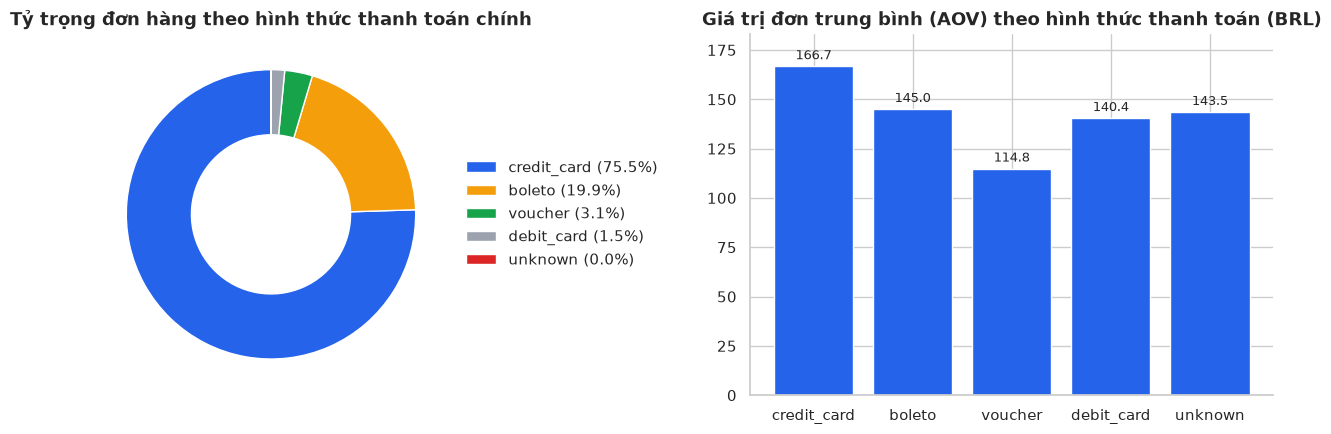

% đơn có dùng voucher (kể cả kết hợp): 3.8% | % đơn dùng >1 hình thức thanh toán: 2.3%


,payment_type,orders,gmv,aov,avg_installments,orders_share,gmv_share
0,credit_card,73104,12184985.67,166.680,3.554,0.755,0.785
1,boleto,19243,2790227.25,145.000,1.000,0.199,0.180
2,voucher,3000,344396.26,114.799,1.146,0.031,0.022
3,debit_card,1469,206253.77,140.404,1.000,0.015,0.013
4,unknown,1,143.46,143.460,NaN,0.000,0.000


In [16]:
pay = add_share(q("""
SELECT payment_type, count(*) AS orders, sum(gmv) AS gmv, avg(gmv) AS aov, avg(installments) AS avg_installments
FROM orders_valid GROUP BY 1 ORDER BY orders DESC"""), "orders", "gmv")
pay_mix = q("SELECT avg(used_voucher) AS voucher, avg(CAST(n_payment_types > 1 AS INTEGER)) AS multi_type FROM orders_valid").iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
wedges, _ = axes[0].pie(pay.orders_share, startangle=90,
                        colors=[C_MAIN, C_ACCENT, C_GOOD, C_GREY, C_BAD][:len(pay)], wedgeprops={"width": 0.45})
axes[0].legend(wedges, [f"{t} ({s:.1%})" for t, s in zip(pay.payment_type, pay.orders_share)],
               loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
axes[0].set_title("Tỷ trọng đơn hàng theo hình thức thanh toán chính")
axes[1].bar(pay.payment_type, pay.aov, color=C_MAIN); axes[1].set_title("Giá trị đơn trung bình (AOV) theo hình thức thanh toán (BRL)")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f", padding=3, fontsize=9); axes[1].margins(y=0.1)
plt.tight_layout(); plt.show()
print(f"% đơn có dùng voucher (kể cả kết hợp): {pay_mix.voucher:.1%} | % đơn dùng >1 hình thức thanh toán: {pay_mix.multi_type:.1%}")
pay.round(3)

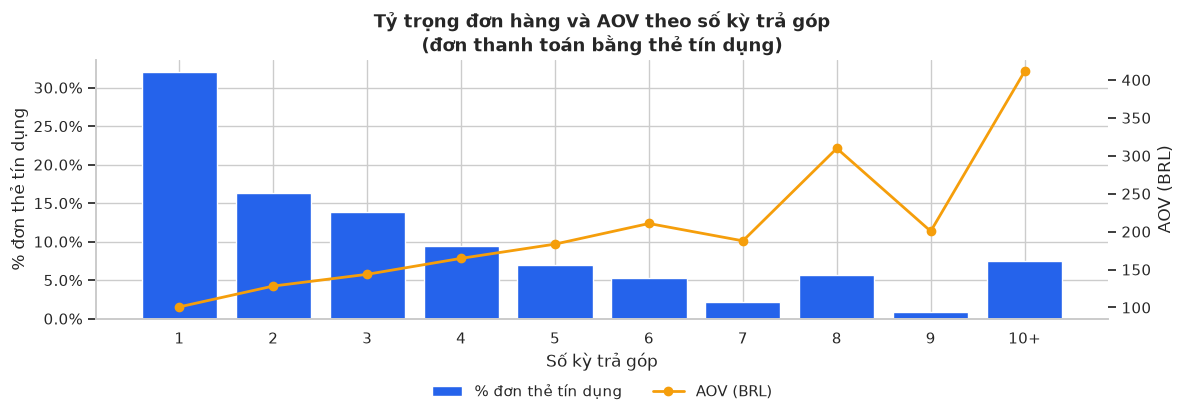

% đơn thẻ tín dụng trả góp (>1 kỳ): 68.0% — chiếm 80.6% doanh thu thẻ


,inst_b,orders,aov,gmv,orders_share,gmv_share,label
0,1,23424,100.802,2361184.37,0.320,0.194,1
1,2,11965,128.253,1534551.30,0.164,0.126,2
2,3,10110,143.740,1453209.89,0.138,0.119,3
3,4,6862,164.773,1130674.10,0.094,0.093,4
4,5,5081,183.549,932610.37,0.070,0.077,5
5,6,3817,210.719,804316.20,0.052,0.066,6
6,7,1585,187.833,297715.80,0.022,0.024,7
7,8,4130,309.781,1279395.03,0.056,0.105,8
8,9,616,200.503,123509.93,0.008,0.010,9
9,10,5514,411.284,2267818.68,0.075,0.186,10+


In [17]:
inst = add_share(q("""
SELECT least(greatest(installments, 1), 10) AS inst_b, count(*) AS orders, avg(gmv) AS aov, sum(gmv) AS gmv
FROM orders_valid WHERE payment_type = 'credit_card'
GROUP BY 1 ORDER BY 1"""), "orders", "gmv")
inst["label"] = inst.inst_b.astype(int).astype(str).replace({"10": "10+"})

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(inst.label, inst.orders_share, color=C_MAIN, label="% đơn thẻ tín dụng"); pct_axis(ax)
ax2 = ax.twinx(); ax2.plot(inst.label, inst.aov, color=C_ACCENT, marker="o", lw=2, label="AOV (BRL)"); ax2.grid(False)
ax.set_title("Tỷ trọng đơn hàng và AOV theo số kỳ trả góp\n(đơn thanh toán bằng thẻ tín dụng)"); ax.set_xlabel("Số kỳ trả góp")
ax.set_ylabel("% đơn thẻ tín dụng"); ax2.set_ylabel("AOV (BRL)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.tight_layout(); plt.show()
inst_multi = inst[inst.inst_b > 1]
print(f"% đơn thẻ tín dụng trả góp (>1 kỳ): {inst_multi.orders_share.sum():.1%} — chiếm {inst_multi.gmv_share.sum():.1%} doanh thu thẻ")
inst.round(3)

> **Nhận xét:**
> - Thẻ tín dụng thống trị: ~75% số đơn, ~78% doanh thu, AOV ~R$ 167. Boleto (phiếu thanh toán) ~20% đơn; voucher 3,1%, thẻ ghi nợ 1,5%.
> - 68% đơn thẻ tín dụng là trả góp, chiếm 81% doanh thu thẻ.
> - AOV tăng mạnh theo số kỳ: 1 kỳ ~R$ 101 → 10+ kỳ ~R$ 411. Có các "đỉnh" số đơn ở 8 kỳ và 10+ kỳ — mốc trả góp phổ biến mà người bán đưa ra. → Trả góp là đòn bẩy tăng giá trị giỏ hàng; nên duy trì/khuyến khích trả góp không lãi cho đơn giá trị cao.

## 7. Mua lặp lại — khách có quay lại không?

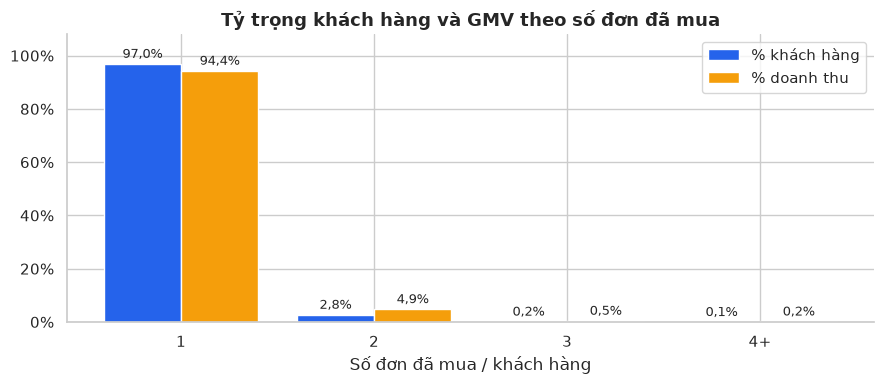

In [18]:
freq = add_share(q("""
SELECT CASE WHEN frequency >= 4 THEN '4+' ELSE CAST(frequency AS VARCHAR) END AS f,
       count(*) AS customers, sum(monetary) AS gmv, avg(monetary) AS clv
FROM cust_base GROUP BY 1 ORDER BY 1"""), "customers", "gmv")

fig, ax = plt.subplots(figsize=(9, 4))
grouped_bar(ax, freq.f, {"% khách hàng": (freq.customers_share, C_MAIN), "% doanh thu": (freq.gmv_share, C_ACCENT)})
for bars in ax.containers:  # ghi giá trị trên cột để đọc được cả các cột rất thấp
    ax.bar_label(bars, labels=[pct(v, 1) for v in bars.datavalues], padding=2, fontsize=9)
ax.set_xlabel("Số đơn đã mua / khách hàng"); ax.set_ylim(0, 1.08); pct_axis(ax, decimals=0)
ax.set_title("Tỷ trọng khách hàng và GMV theo số đơn đã mua")
plt.tight_layout(); plt.show()

>**Nhận xét:** 97% khách chỉ mua 1 lần. Tỷ lệ giữ chân khách hàng đang rất thấp -> Cần có chiến lược để cân bằng giữa việc giữ chân khách hàng cũ và thu hút khách hàng mới.

Khách có đơn thứ 2: 2,830 | Trung vị thời gian tới đơn thứ 2 (bỏ cùng ngày): 75 ngày


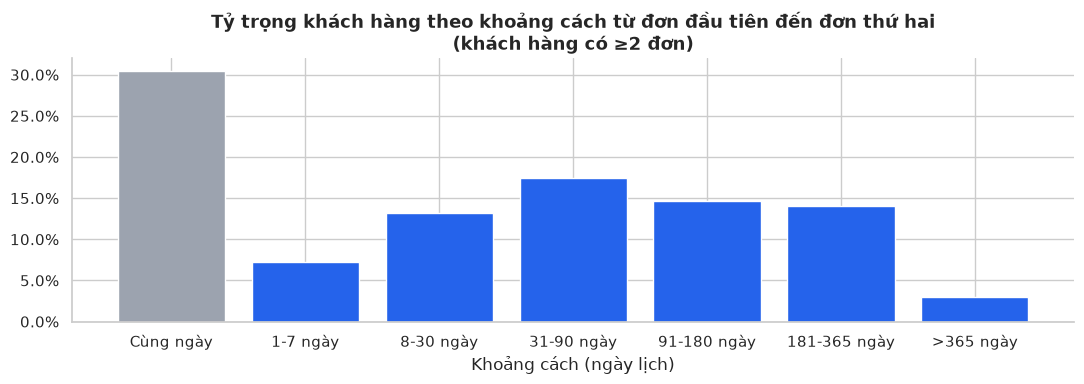

In [19]:
GAP_BINS = [(0, "Cùng ngày"), (7, "1-7 ngày"), (30, "8-30 ngày"), (90, "31-90 ngày"), (180, "91-180 ngày"), (365, "181-365 ngày")]
GAP_ORDER = [label for _, label in GAP_BINS] + [">365 ngày"]
t2 = q(f"""
SELECT {band_sql("days_to_2nd_order", GAP_BINS, ">365 ngày", upper_inclusive=True)} AS bucket, count(*) AS customers
FROM cust_base WHERE days_to_2nd_order IS NOT NULL GROUP BY 1""")
t2 = add_share(ordered(t2, "bucket", GAP_ORDER, drop_missing=True), "customers")
gap = q(f"""
SELECT count(*) AS n_2nd,
       {median_sql("days_to_2nd_order", where="days_to_2nd_order >= 1")}               AS median_days,
       avg(CAST(days_to_2nd_order <= 90 AS INTEGER)) FILTER (WHERE days_to_2nd_order >= 1) AS within_90
FROM cust_base WHERE days_to_2nd_order IS NOT NULL""").iloc[0]
print(f"Khách có đơn thứ 2: {gap.n_2nd:,.0f} | Trung vị thời gian tới đơn thứ 2 (bỏ cùng ngày): {gap.median_days:.0f} ngày")

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(t2.bucket, t2.customers_share, color=[C_GREY] + [C_MAIN] * (len(t2) - 1)); pct_axis(ax)
ax.set_title("Tỷ trọng khách hàng theo khoảng cách từ đơn đầu tiên đến đơn thứ hai\n(khách hàng có ≥2 đơn)")
ax.set_xlabel("Khoảng cách (ngày lịch)")
plt.tight_layout(); plt.show()

>**Nhận xét:**
> - 30% "đơn thứ hai" xảy ra cùng ngày với đơn đầu (khách tách đơn / mua thêm ngay) — không phải hành vi quay lại thật.
> - Với khách quay lại thật (bỏ đơn cùng ngày), trung vị ~75 ngày và 55% quay lại trong vòng 90 ngày. → Cửa sổ vàng để remarketing là 1–3 tháng sau đơn đầu.

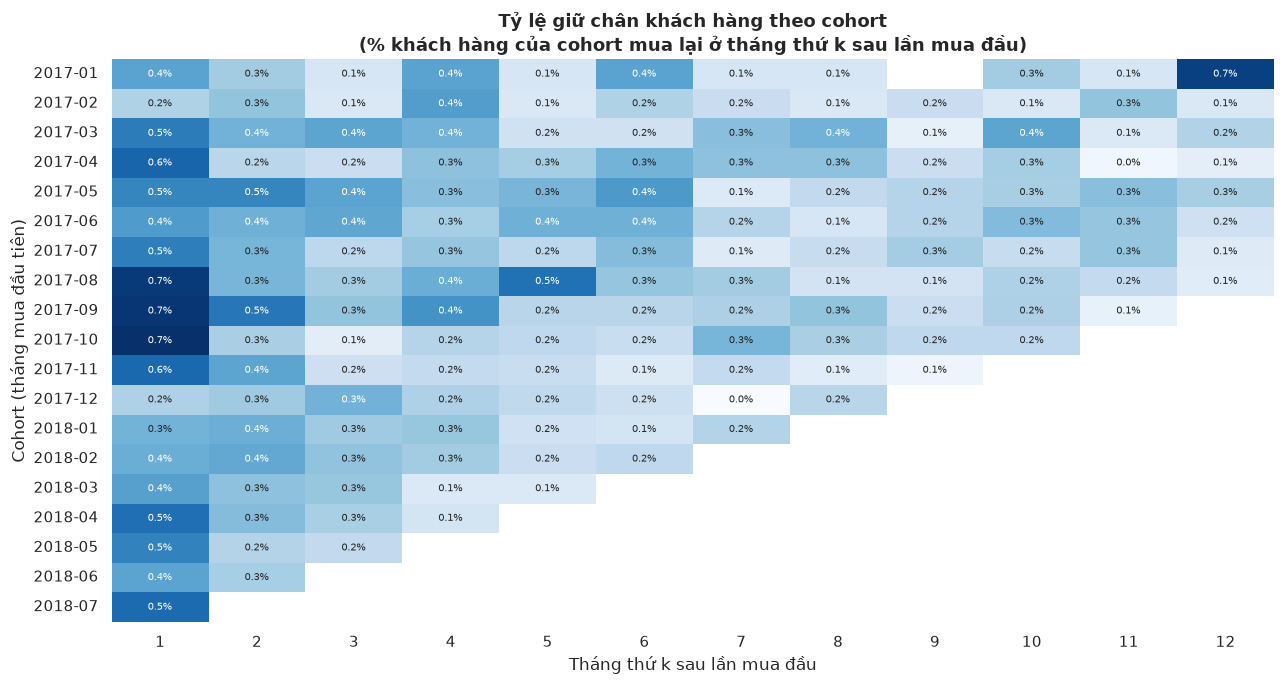

Retention TB tháng 1 / 3 / 6: M1: 0.48%, M3: 0.25%, M6: 0.25%


In [20]:
coh = q(f"""
SELECT c.cohort_month,
       date_diff('month', c.cohort_month, o.purchase_month) AS month_idx,
       count(DISTINCT o.customer_key) AS customers
FROM orders_valid o JOIN cust_base c ON c.customer_key = o.customer_key
WHERE c.cohort_month BETWEEN DATE '{P.m_start}' AND DATE '{P.m_end}' AND o.purchase_month <= DATE '{P.m_end}'
GROUP BY 1, 2""")
size = coh[coh.month_idx == 0].set_index("cohort_month").customers
coh["retention"] = coh.customers / coh.cohort_month.map(size)
ret = coh[(coh.month_idx >= 1) & (coh.month_idx <= 12)].pivot(index="cohort_month", columns="month_idx", values="retention")
ret.index = pd.to_datetime(ret.index).strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(ret, annot=True, fmt=".1%", cmap="Blues", ax=ax, cbar=False, annot_kws={"fontsize": 7}); ax.grid(False)
ax.set_title("Tỷ lệ giữ chân khách hàng theo cohort\n(% khách hàng của cohort mua lại ở tháng thứ k sau lần mua đầu)")
ax.set_xlabel("Tháng thứ k sau lần mua đầu"); ax.set_ylabel("Cohort (tháng mua đầu tiên)")
plt.tight_layout(); plt.show()
print("Retention TB tháng 1 / 3 / 6:", ", ".join(f"M{m}: {ret[m].mean():.2%}" for m in [1, 3, 6] if m in ret))

>**Nhận xét:** Tỷ lệ giữ chân khách hàng từng tháng của mọi cohort trung vị chỉ 0,26% — không cohort nào tạo được nhóm khách trung thành. Cohort Black Friday (2017-11) giữ chân M1–M3 TB 0,37%, ngang mức TB 0,36% của mọi cohort: khách mua dịp khuyến mãi không kém trung thành hơn, nhưng cũng không tốt hơn.

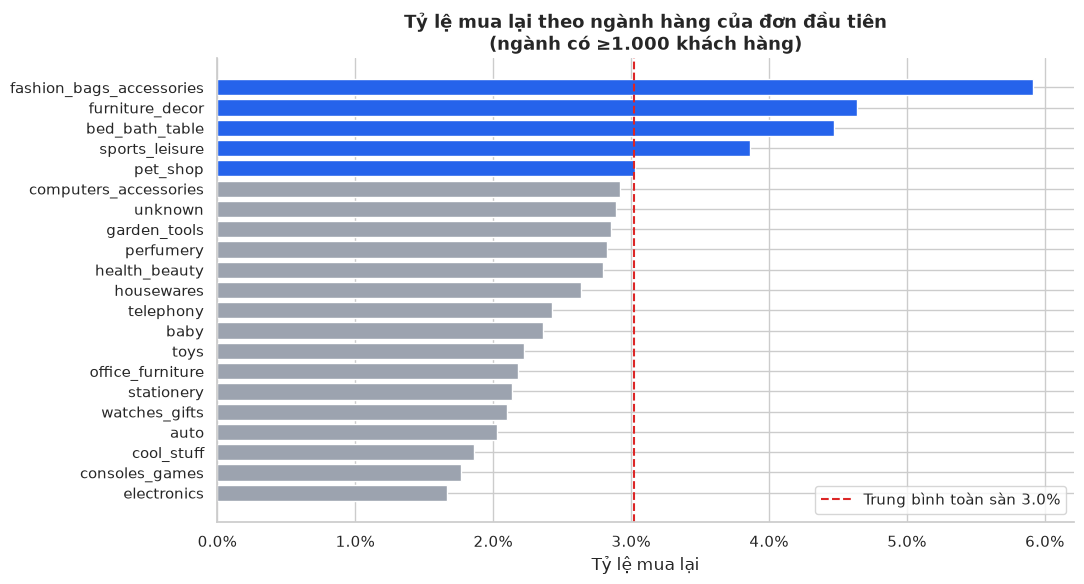

In [21]:
rep_cat = q("""
SELECT first_category, count(*) AS customers, avg(CAST(is_repeat AS INTEGER)) AS repeat_rate
FROM cust_base GROUP BY 1 HAVING count(*) >= 1000 ORDER BY repeat_rate DESC""")
overall_rr = kc.repeat_rate
fig, ax = plt.subplots(figsize=(11, 6))
r = rep_cat.iloc[::-1]
ax.barh(r.first_category, r.repeat_rate, color=[C_MAIN if v >= overall_rr else C_GREY for v in r.repeat_rate])
ax.axvline(overall_rr, color=C_BAD, ls="--", label=f"Trung bình toàn sàn {overall_rr:.1%}"); pct_axis(ax, "x"); ax.legend()
ax.set_title("Tỷ lệ mua lại theo ngành hàng của đơn đầu tiên\n(ngành có ≥1.000 khách hàng)"); ax.set_xlabel("Tỷ lệ mua lại")
plt.tight_layout()
plt.show()

> **Nhận xét:** Khách có đơn đầu thuộc fashion_bags_accessories (5,9%), furniture_decor (4,7%), bed_bath_table (4,4%), sports_leisure (3,9%) quay lại nhiều hơn trung bình (3,0%). Thấp nhất là cool_stuff, consoles_games, electronics — hàng mua một lần.

## 8. Tổng kết
1. **Sàn sống nhờ khách mới:** 97% khách chỉ mua 1 lần, khách mua lại chỉ tạo 5,7% doanh thu; khách mới mỗi tháng ở 2018 đã chững (§1, §2).
2. **Hai nhóm RFM cần ưu tiên ngân sách:** "Khách mới" (39% khách, 39% doanh thu) cần kích hoạt đơn thứ 2; "Giá trị cao sắp mất" (15% khách, 27% doanh thu) cần win-back (§3).
3. **Giỏ hàng nhỏ và gần như không có bán chéo:** 90% đơn chỉ 1 sản phẩm; đơn < R$ 50 chịu phí ship 35% giá trị → dư địa cho freeship theo ngưỡng / combo (§5).
4. **Cửa sổ remarketing là 1–3 tháng sau đơn đầu** (trung vị 75 ngày tới đơn thứ 2); trả góp là đòn bẩy cho đơn giá trị cao (§6, §7).

In [22]:
con.close()